# 01 — Train model (end-to-end)

Notebook mẫu cho mọi model phân loại nhị phân (credit score, propensity...). Chạy từ trên xuống dưới:

| Bước | Nội dung | Hàm chính |
|---|---|---|
| 1 | Load data | `make_synthetic_dataset` (thay bằng data thật) |
| 2 | Phân tích label | `label_summary` |
| 3 | Chia train / val / test theo thời gian | `time_split` |
| 4 | Xử lý missing | `fill_missing` |
| 5 | **Hard selection** — loại cột vô dụng theo luật | `HardFeatureSelector` |
| 5b | **Ổn định theo thời gian** — quan hệ feature↔label có giữ chiều qua các tháng | `TemporalStabilitySelector` |
| 6 | **Soft selection** — 10 tiêu chí bỏ phiếu | `SoftFeatureSelector` |
| 6b | **Shadow check** — importance phải vượt mức nhiễu của bản xáo trộn | `ShadowFeatureSelector` |
| 7 | Forward selection — chọn số feature tối ưu | `forward_selection_gini`, `best_k` |
| 8 | Train CatBoost | `train_catboost` |
| 9 | Đánh giá: Gini, ROC, decile, PSI, calibration | `evaluate_splits`, `decile_table`, `psi`, `calibration_summary` |
| 10 | SHAP | `shap_importance` |
| 10a | Drift: event PSI, PSI theo trọng số model, SHAP drift | `psi_report`, `shap_drift` |
| 10b | Challenger: scorecard logistic (+ luật tương tác) + so sánh champion/challenger (DeLong) | `LogisticScorecard`, `TreeRuleMiner`, `compare_models` |
| 10c | Ablation — mỗi feature đóng góp bao nhiêu Gini | `LogisticScorecard.ablation`, `refit_ablation` |
| 11 | Quy đổi điểm 300–850 | `fit_score_bounds`, `proba_to_score` |
| 12 | Lưu model | `ModelBundle.save` |

Mọi tham số nằm trong `configs/model_config.yaml`. Làm model mới: copy file config, sửa, rồi đổi đường dẫn ở cell Setup.

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# Notebook chạy từ thư mục notebooks/ hoặc từ root repo đều được
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

from train_model.config import load_config

cfg = load_config(ROOT / "configs" / "model_config.yaml")
TARGET, DATE, GROUP, ID = cfg.model.target_col, cfg.model.date_col, cfg.model.group_col, cfg.model.id_col
CAT_COLS = cfg.features.cat_cols
print("model:", cfg.model.model_code, "| target:", TARGET, "| cat:", CAT_COLS)

model: demo_cs_v1 | target: GB | cat: ['device_manu', 'sub_type', 'demographic_province_l1m']


## 1. Load data

Ở đây dùng **data giả lập** để notebook chạy được ở mọi máy. Data giả có sẵn các cột "bẫy"
(cột hằng, cột trùng, cột tương quan cao, cột missing nhiều, cột nhiễu) để xem selection có loại đúng không.

Với data thật, thay cell dưới bằng ví dụ:
```python
df = pd.read_parquet("path/to/model_dataset.parquet")
```

In [2]:
from train_model.data import make_synthetic_dataset

df = make_synthetic_dataset(n_rows=8000, n_months=12, seed=42)
print(df.shape)
df.head()

(8000, 24)


,msisdn,date,client,usage_data_mb_l1m,usage_data_mb_l3m,recharge_amt_l1m,recharge_cnt_l3m,voice_out_min_l1m,sms_out_cnt_l1m,demographic_age_l1m,device_manu,sub_type,demographic_province_l1m,GB,noise_1,noise_2,noise_3,noise_4,noise_5,const_col,dup_of_usage,corr_of_recharge,mostly_missing,all_missing
0,85600534523,20240801,B,700.087419,3012.917970,124338.151530,8.0,148.504544,13.0,31.0,apple,prepaid,p06,0,0.025490,-0.590830,0.611521,-0.134448,1.861512,1.0,700.087419,125516.504703,NaN,NaN
1,85600925917,20240801,B,328.627867,750.936247,118993.046381,8.0,5.303289,14.0,33.0,other brands,prepaid,p04,0,-0.373842,0.605550,-1.029154,0.362932,-0.738015,1.0,328.627867,120080.736552,NaN,NaN
2,85601180882,20240801,A,2617.273675,5787.065248,223691.165832,8.0,NaN,20.0,56.0,vivo,prepaid,p10,1,1.915146,0.675965,-0.853214,0.767126,-0.172188,1.0,2617.273675,225765.254755,NaN,NaN
3,85601340674,20240801,A,112.411211,400.398070,70514.519053,6.0,75.825013,15.0,54.0,oppo,prepaid,p04,1,0.107368,-0.776490,-1.130003,-0.412879,0.278360,1.0,112.411211,71184.368057,NaN,NaN
4,85601390630,20240801,A,2546.112083,3609.289994,86559.526619,7.0,113.346725,16.0,18.0,samsung,prepaid,p07,1,-0.205709,0.202949,0.117055,-1.426316,1.475633,1.0,2546.112083,87604.635811,NaN,NaN


## 2. Phân tích label

,count,n_positive,rate
0,8000,2772,0.3465


,client,count,n_positive,rate
0,A,4701,1639,0.348649
1,B,3299,1133,0.343437


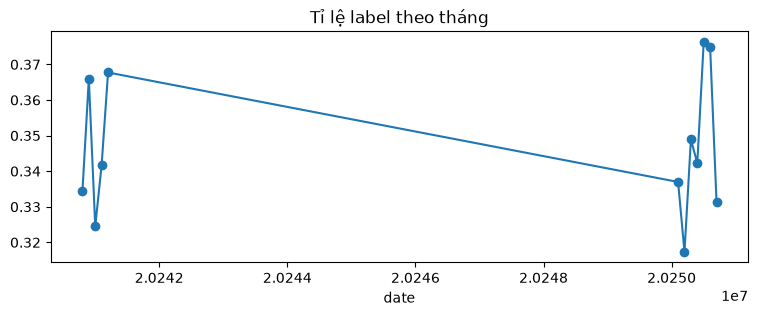

In [3]:
from train_model.data import label_summary

lab = label_summary(df, TARGET, DATE, GROUP)
display(lab["overall"])
display(lab["by_group"])
lab["by_month"].plot(x=DATE, y="rate", marker="o", figsize=(9, 3), title="Tỉ lệ label theo tháng", legend=False);

## 3. Chia train / val / test

* **test** = các tháng `>= split_date` (out-of-time) — đo model có ổn định theo thời gian không.
* **val** = lấy ngẫu nhiên từ phần trước `split_date` — dùng cho early stopping và selection.

`split_date` có thể là dict theo client: `{A: 20250601, B: 20250701}`.

In [4]:
from train_model.data import time_split

train_raw, val_raw, test_raw = time_split(
    df, DATE, cfg.split.split_date, val_size=cfg.split.val_size, seed=cfg.split.seed,
    group_col=GROUP, target_col=TARGET,
)
for name, d in [("train", train_raw), ("val", val_raw), ("test", test_raw)]:
    print(f"{name:5s} {d.shape}  label rate = {d[TARGET].mean():.3f}  months = {[int(m) for m in sorted(d[DATE].unique())]}")

train (4808, 24)  label rate = 0.342  months = [20240801, 20240901, 20241001, 20241101, 20241201, 20250101, 20250201, 20250301, 20250401]
val   (1202, 24)  label rate = 0.342  months = [20240801, 20240901, 20241001, 20241101, 20241201, 20250101, 20250201, 20250301, 20250401]
test  (1990, 24)  label rate = 0.360  months = [20250501, 20250601, 20250701]


## 4. Xử lý missing

Cột categorical: trim + lower, rỗng/NaN → `cat_fill`. Cột số: giữ NaN (CatBoost tự xử lý) trừ khi config đặt `num_fill`.
Quy tắc này được lưu vào model để lúc predict (pandas hay Spark) xử lý y hệt.

In [5]:
from train_model.preprocessing import fill_missing

fill = dict(cat_cols=CAT_COLS, cat_fill=cfg.features.cat_fill, num_fill=cfg.features.num_fill)
train, val, test = (fill_missing(d, **fill) for d in (train_raw, val_raw, test_raw))

candidates = cfg.feature_columns(list(train.columns))
print(len(candidates), "candidate features")

20 candidate features


## 5. Hard selection

Loại theo luật, lần lượt:

1. `missing` — tỉ lệ missing > `missing_threshold`
2. `constant` — một giá trị chiếm ≥ `quasi_constant_tol`
3. `duplicate` — trùng hoàn toàn với cột khác
4. `low_iv` — Information Value < `iv_threshold`
5. `high_corr` — cặp |corr| > `corr_threshold` → bỏ cột có IV thấp hơn

`report_` cho biết cột nào bị loại ở bước nào và vì sao.

Giữ 10/20 features


,feature,step,value
0,mostly_missing,missing,0.980241
1,all_missing,missing,1.0
2,const_col,constant,1.0
3,dup_of_usage,duplicate,usage_data_mb_l1m
4,demographic_province_l1m,low_iv,0.004728
5,noise_1,low_iv,0.01053
6,noise_2,low_iv,0.00902
7,noise_4,low_iv,0.013329
8,noise_5,low_iv,0.013726
9,recharge_amt_l1m,high_corr,0.999999


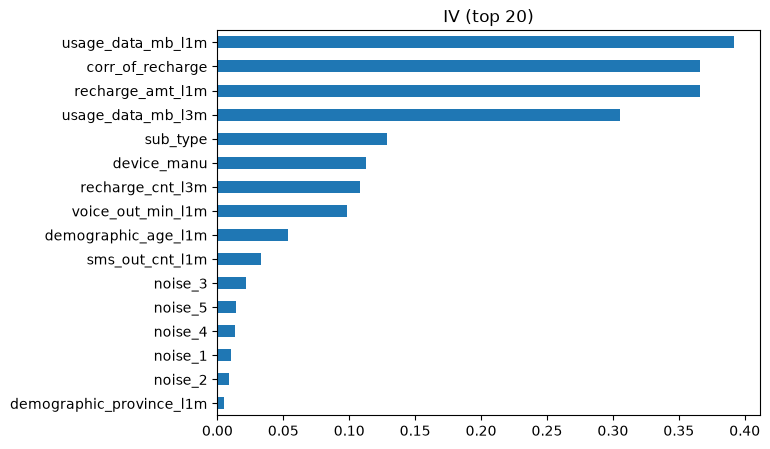

In [6]:
from train_model.feature_selection import HardFeatureSelector

hard = HardFeatureSelector(cat_cols=CAT_COLS, **cfg.hard_selection)
hard.fit(train[candidates], train[TARGET])

print(f"Giữ {len(hard.selected_features_)}/{len(candidates)} features")
display(hard.report_)
hard.iv_.sort_values(ascending=False).head(20).plot.barh(figsize=(7, 5), title="IV (top 20)").invert_yaxis()

## 5b. Ổn định theo thời gian — `TemporalStabilitySelector`

PSI chỉ kiểm tra **phân phối** của feature. Bước này kiểm tra **quan hệ với label** có ổn định không:
mỗi bin của feature, mỗi tháng tính `TR = tỉ lệ label của bin / tỉ lệ label của tháng − 1`.
Feature tốt giữ mỗi bin **luôn cùng một phía** so với trung bình tháng (luôn trên, hoặc luôn dưới).

* `score` = 1 → mọi bin luôn giữ chiều · 0 → bin đổi chiều ngẫu nhiên (dễ overfit theo thời điểm)
* Loại feature có `score < threshold` trên **train hoặc val** (`status = unstable`). Val là mẫu thứ hai độc lập, giúp tránh feature "ổn định" do may mắn.
  **Không** đưa tập test vào đây: chọn feature bằng nhãn của test làm Gini test bị ảo (leakage).
* `no_signal` (không bin nào tách được label) / `insufficient_time` (< 2 tháng) — không đánh giá được, mặc định giữ

> Data giả lập có quan hệ feature↔label **không đổi** theo thời gian nên bước này không loại feature nào — đó là kết quả đúng.
> Trên data thật (hành vi khách đổi theo mùa, chính sách, kênh) bước này thường loại được vài feature mà IV/PSI không bắt được.

Ý tưởng từ bước *WOE Stabilizer* của [AIDflow](https://github.com/aigensys-labs/aidflow), viết lại (xem docstring `train_model/feature_selection/stability.py`).

Giữ 10/10 features


,feature,score,status,n_bins,score_val,status_val,keep
0,recharge_cnt_l3m,1.0,stable,2,1.0,stable,True
1,usage_data_mb_l3m,1.0,stable,5,NaN,insufficient_time,True
2,usage_data_mb_l1m,1.0,stable,5,NaN,no_signal,True
3,voice_out_min_l1m,1.0,stable,4,NaN,insufficient_time,True
4,demographic_age_l1m,1.0,stable,1,NaN,no_signal,True
5,device_manu,1.0,stable,2,1.0,stable,True
6,corr_of_recharge,1.0,stable,6,1.0,stable,True
7,sms_out_cnt_l1m,1.0,stable,3,1.0,stable,True
8,sub_type,1.0,stable,2,1.0,stable,True
9,noise_3,NaN,no_signal,0,NaN,no_signal,True


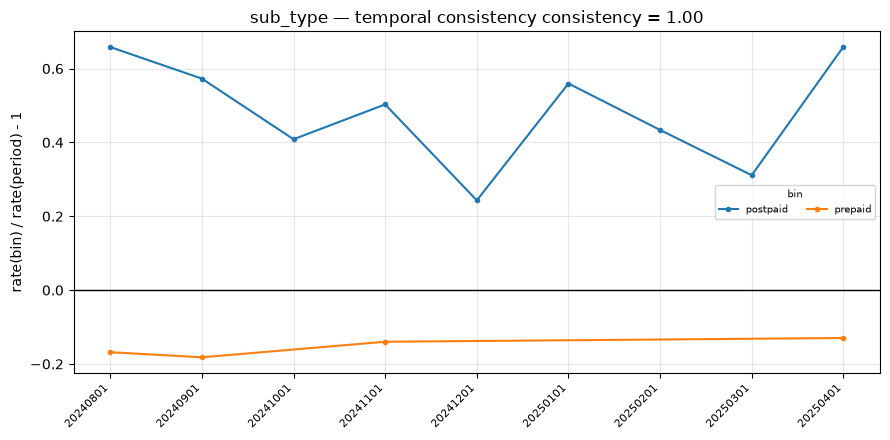

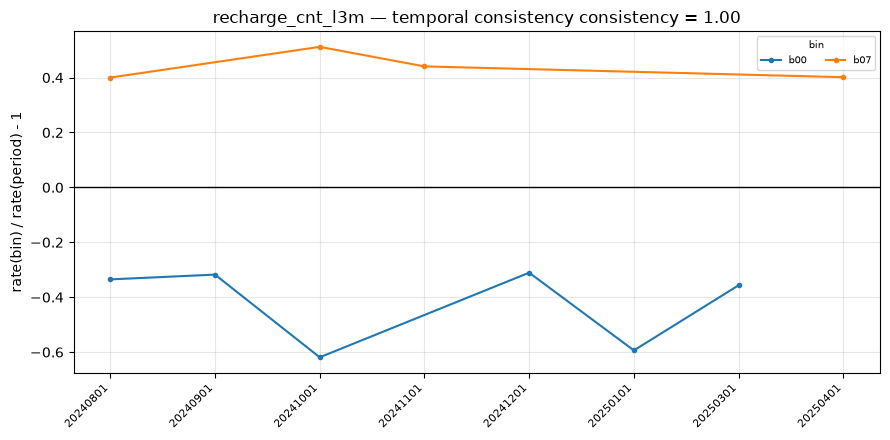

In [7]:
from train_model.evaluation import plot_temporal_consistency
from train_model.feature_selection import TemporalStabilitySelector

hard_feats = hard.selected_features_
stab = TemporalStabilitySelector(time_col=DATE, cat_cols=CAT_COLS, **cfg.stability)
stab.fit(train[hard_feats + [DATE]], train[TARGET], val[hard_feats + [DATE]], val[TARGET])

print(f"Giữ {len(stab.selected_features_)}/{len(hard_feats)} features")
display(stab.report_.round(3))

# feature ổn định nhất và kém nhất (có điểm) trên train
scored = stab.report_.dropna(subset=["score"])
for f in [scored.iloc[-1]["feature"], scored.iloc[0]["feature"]]:
    s = scored.set_index("feature").loc[f, "score"]
    plot_temporal_consistency(stab.tables_[f], f, s)

## 6. Soft selection — bỏ phiếu

Mỗi tiêu chí cho feature một phiếu (✔). Feature đạt **≥ `min_votes`** phiếu được giữ.

| Tiêu chí | Được phiếu khi |
|---|---|
| correlation | top-k \|tương quan\| với label |
| permutation | top-k AUC giảm khi xáo trộn feature (validation) |
| single_feature | top-k AUC khi train chỉ 1 feature |
| tree_importance | top-k importance của RandomForest |
| tree_vs_random | importance > cột ngẫu nhiên |
| variance | variance > ngưỡng |
| mutual_info | top % mutual information |
| l1 / l2 | được Logistic L1 / L2 giữ lại |
| rfe | được RFE chọn |

Tắt tiêu chí nào: xoá khỏi `soft_selection.criteria` trong config.

In [8]:
from train_model.feature_selection import SoftFeatureSelector

stable_feats = stab.selected_features_
soft = SoftFeatureSelector(cat_cols=CAT_COLS, **cfg.soft_selection)
soft.fit(train[stable_feats], train[TARGET], val[stable_feats], val[TARGET])

print(f"Giữ {len(soft.selected_)}/{len(stable_feats)} features (min_votes={soft.min_votes})")
soft.votes_.replace({True: "✔", False: ""})

Giữ 10/10 features (min_votes=3)


,correlation,permutation,single_feature,tree_importance,tree_vs_random,variance,mutual_info,l1,l2,rfe,n_votes
corr_of_recharge,✔,✔,✔,✔,✔,✔,✔,✔,✔,✔,10
device_manu,✔,✔,✔,✔,✔,✔,✔,✔,✔,✔,10
sub_type,✔,✔,✔,✔,✔,✔,✔,✔,✔,✔,10
usage_data_mb_l1m,✔,✔,✔,✔,✔,✔,✔,✔,✔,✔,10
usage_data_mb_l3m,✔,✔,✔,✔,✔,✔,✔,✔,✔,✔,10
voice_out_min_l1m,✔,✔,✔,✔,✔,✔,✔,✔,✔,✔,10
demographic_age_l1m,✔,✔,✔,✔,✔,✔,,✔,✔,✔,9
recharge_cnt_l3m,✔,✔,✔,✔,✔,✔,,✔,✔,✔,9
sms_out_cnt_l1m,✔,✔,✔,✔,✔,✔,,✔,✔,✔,9
noise_3,✔,✔,✔,✔,✔,✔,,,,✔,7


## 6b. Shadow check — `ShadowFeatureSelector`

Mỗi feature có một bản **shadow** = chính nó bị xáo trộn ngẫu nhiên (cùng phân phối, không liên quan label).
Train CatBoost trên feature thật + shadow (`n_shadows` lần xáo × `cv` fold), đo mean |SHAP| trên fold kiểm tra.
Mức nhiễu mỗi lần = quantile `quantile` (0.9) của importance các shadow. Giữ feature có importance trung bình **vượt mức nhiễu trung bình**.
`share_runs_above` = tỉ lệ lần chạy feature vượt mức nhiễu — thấp là feature sát ngưỡng.

Chặt hơn tiêu chí `tree_vs_random` (chỉ 1 cột ngẫu nhiên, 1 lần fit). Ý tưởng từ *FeaturesShadowPruner* của [AIDflow](https://github.com/aigensys-labs/aidflow), viết lại.

In [9]:
from train_model.feature_selection import ShadowFeatureSelector

soft_feats = soft.selected_ or soft.votes_.index.tolist()
shadow = ShadowFeatureSelector(cat_cols=CAT_COLS, random_state=cfg.split.seed, **cfg.shadow)
shadow.fit(train[soft_feats], train[TARGET])
print(f"Giữ {len(shadow.selected_features_)}/{len(soft_feats)} features | mức nhiễu = {shadow.threshold_:.4f}")
display(shadow.report_.round(4))

Giữ 10/10 features | mức nhiễu = 0.0603


,feature,mean_importance,std_importance,threshold,share_runs_above,keep
0,corr_of_recharge,0.5978,0.0212,0.0603,1.0000,True
1,usage_data_mb_l1m,0.4632,0.0305,0.0603,1.0000,True
2,sub_type,0.3585,0.0185,0.0603,1.0000,True
3,recharge_cnt_l3m,0.3419,0.0330,0.0603,1.0000,True
4,usage_data_mb_l3m,0.2836,0.0312,0.0603,1.0000,True
5,voice_out_min_l1m,0.2835,0.0263,0.0603,1.0000,True
6,demographic_age_l1m,0.2512,0.0214,0.0603,1.0000,True
7,device_manu,0.2266,0.0373,0.0603,1.0000,True
8,sms_out_cnt_l1m,0.1425,0.0170,0.0603,1.0000,True
9,noise_3,0.0642,0.0174,0.0603,0.6667,True


## 7. Forward selection

Thêm dần feature theo thứ tự số phiếu, train CatBoost mỗi lần và đo Gini trên validation.
`best_k` = số feature ít nhất mà Gini chỉ kém Gini cao nhất ≤ `tolerance`.

final features: ['corr_of_recharge', 'device_manu', 'sub_type', 'usage_data_mb_l1m', 'usage_data_mb_l3m', 'voice_out_min_l1m', 'demographic_age_l1m', 'recharge_cnt_l3m', 'sms_out_cnt_l1m']


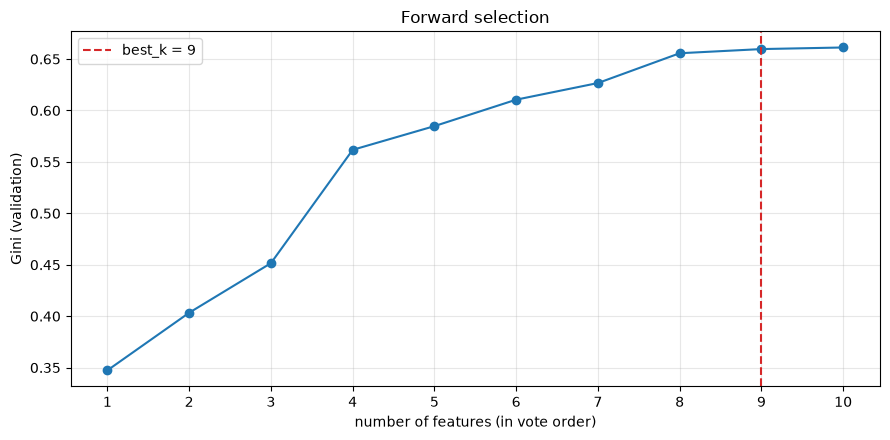

In [10]:
from train_model.evaluation import plot_forward_gini
from train_model.feature_selection import best_k, forward_selection_gini

ordered = [f for f in soft_feats if f in shadow.selected_features_]  # thứ tự số phiếu, đã qua shadow check
fwd = forward_selection_gini(
    train, train[TARGET], val, val[TARGET], ordered, cat_cols=CAT_COLS,
    catboost_params={"iterations": 300},
)
k = best_k(fwd, tolerance=0.005)
final_features = ordered[:k]
plot_forward_gini(fwd, best=k)
print("final features:", final_features)

## 8. Train CatBoost

In [11]:
from train_model.modeling import train_catboost

cat_final = [c for c in final_features if c in CAT_COLS]
model = train_catboost(
    train, val, final_features, TARGET, cat_features=cat_final,
    params=cfg.catboost, seed=cfg.split.seed,
)
print("best iteration:", model.get_best_iteration(), "| trees:", model.tree_count_)

best iteration: 189 | trees: 190


## 9. Đánh giá

,split,n,auc,gini
0,train,4808,0.839022,0.678044
1,val,1202,0.831203,0.662406
2,test,1990,0.799135,0.598269


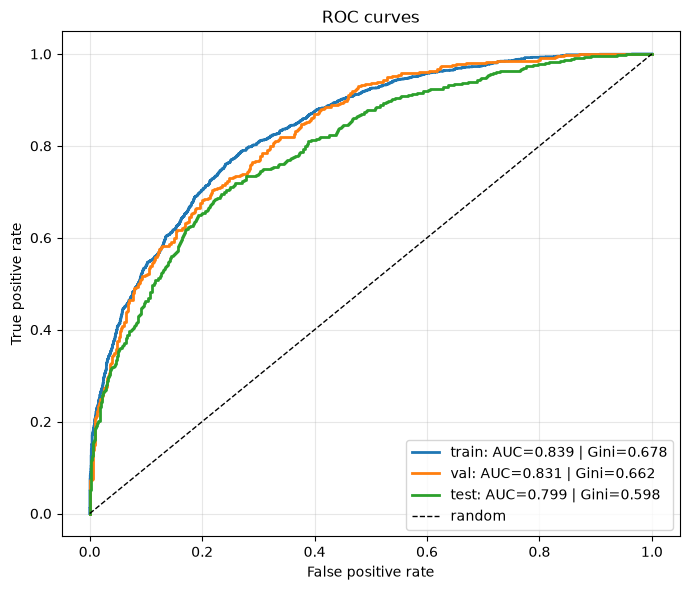

In [12]:
from train_model.evaluation import auc_gini_by_group, decile_table, plot_roc, psi, psi_by_feature
from train_model.modeling import evaluate_splits, prepare_features

splits = {"train": train, "val": val, "test": test}
metrics = evaluate_splits(model, splits, final_features, TARGET)
display(metrics)

proba = {n: model.predict_proba(prepare_features(d, final_features, cat_final))[:, 1] for n, d in splits.items()}
plot_roc({n: (splits[n][TARGET], proba[n]) for n in splits});

### Decile (lift) table trên test — top 1 = nhóm điểm cao nhất

In [13]:
display(decile_table(test[TARGET], proba["test"]))

,top,count,n_positive,acc_positive,positive_rate,acc_positive_rate,cover_positive,proba_range
0,1,199,173,173,0.869347,0.869347,0.241283,"[0.698, 0.976]"
1,2,199,121,294,0.608040,0.738693,0.410042,"[0.575, 0.697]"
2,3,199,111,405,0.557789,0.678392,0.564854,"[0.463, 0.575]"
3,4,199,93,498,0.467337,0.625628,0.694561,"[0.376, 0.463]"
4,5,199,52,550,0.261307,0.552764,0.767085,"[0.307, 0.376]"
5,6,199,58,608,0.291457,0.509213,0.847978,"[0.246, 0.307]"
6,7,199,47,655,0.236181,0.470208,0.913529,"[0.189, 0.245]"
7,8,199,30,685,0.150754,0.430276,0.955370,"[0.136, 0.189]"
8,9,199,23,708,0.115578,0.395310,0.987448,"[0.077, 0.135]"
9,10,199,9,717,0.045226,0.360302,1.000000,"[0.007, 0.076]"


### Gini theo client và theo tháng (test)

In [14]:
test_scored = test.assign(proba=proba["test"])
display(auc_gini_by_group(test_scored, TARGET, "proba", GROUP))
display(auc_gini_by_group(pd.concat([train.assign(proba=proba["train"]), test_scored]), TARGET, "proba", DATE))

,group,n,auc,gini
0,A,1171,0.803848,0.607696
1,B,819,0.790932,0.581864


,group,n,auc,gini
0,20240801,572,0.839123,0.678246
1,20240901,494,0.834537,0.669073
2,20241001,568,0.852398,0.704795
3,20241101,501,0.833926,0.667851
4,20241201,568,0.841335,0.682669
5,20250101,517,0.859960,0.719919
6,20250201,525,0.849611,0.699221
7,20250301,494,0.814057,0.628113
8,20250401,569,0.823104,0.646209
9,20250501,675,0.799633,0.599267


### PSI — độ ổn định phân phối

< 0.1 ổn định · 0.1–0.25 lệch vừa · > 0.25 lệch mạnh

In [15]:
print(f"PSI proba train vs test: {psi(proba['train'], proba['test']):.4f}")
display(psi_by_feature(train, test, final_features))

PSI proba train vs test: 0.0086


,feature,psi
0,usage_data_mb_l3m,0.014329
1,sms_out_cnt_l1m,0.010154
2,corr_of_recharge,0.009567
3,voice_out_min_l1m,0.009506
4,usage_data_mb_l1m,0.004374
5,recharge_cnt_l3m,0.003606
6,demographic_age_l1m,0.003505
7,device_manu,0.003093
8,sub_type,0.000991


### Calibration — xác suất dự báo có khớp tỉ lệ thực tế?

Chia xác suất thành 10 bin (quantile), mỗi bin kiểm định z: tỉ lệ label thực tế có khác **có ý nghĩa** so với xác suất trung bình không.
`calibration_score` = tỉ lệ bin **không** lệch có ý nghĩa (1 = khớp mọi bin). `direction`: `over` = model dự báo cao hơn thực tế, `under` = thấp hơn.
Hosmer–Lemeshow là kiểm định chung trên cùng các bin (p < 0.05 → lệch). Gini cao chưa chắc xác suất đúng — quan trọng khi dùng xác suất làm PD.

,calibration_score,hl_stat,hl_p_value,brier,mean_proba,event_rate
train,0.5,70.5702,0.0000,0.1530,0.3413,0.3419
val,0.9,18.8408,0.0157,0.1565,0.3344,0.3419
test,0.8,17.7835,0.0229,0.1702,0.3516,0.3603


,bin,count,proba_mean,event_rate,diff,z,p_value,significant,direction
0,0,199,0.0483,0.0452,-0.0031,-0.2044,0.8381,False,ok
1,1,199,0.1063,0.1156,0.0093,0.4253,0.6706,False,ok
2,2,199,0.1627,0.1508,-0.0119,-0.4548,0.6493,False,ok
3,3,199,0.2159,0.2362,0.0203,0.6946,0.4873,False,ok
4,4,199,0.2748,0.2915,0.0167,0.5272,0.5981,False,ok
5,5,199,0.3407,0.2613,-0.0794,-2.3631,0.0181,True,over
6,6,199,0.4195,0.4673,0.0478,1.3664,0.1718,False,ok
7,7,199,0.5184,0.5578,0.0394,1.1114,0.2664,False,ok
8,8,199,0.6368,0.6080,-0.0288,-0.8447,0.3983,False,ok
9,9,199,0.7922,0.8693,0.0771,2.6820,0.0073,True,under


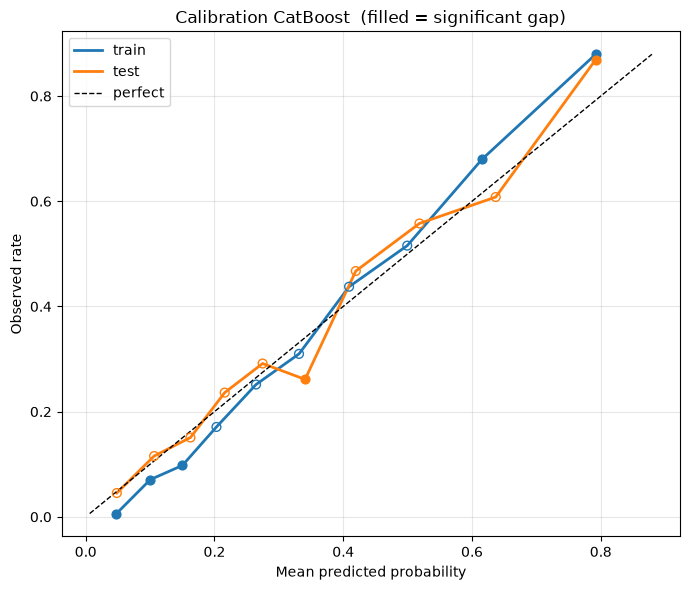

In [16]:
from train_model.evaluation import calibration_summary, calibration_table, plot_calibration

display(pd.DataFrame({n: calibration_summary(splits[n][TARGET], proba[n]) for n in splits}).T.round(4))
display(calibration_table(test[TARGET], proba["test"]).round(4))
plot_calibration({n: (splits[n][TARGET], proba[n]) for n in ("train", "test")}, title="Calibration CatBoost");

## 10. SHAP

,feature,mean_abs_shap
0,corr_of_recharge,0.566903
1,usage_data_mb_l1m,0.433269
2,sub_type,0.346490
3,recharge_cnt_l3m,0.307422
4,voice_out_min_l1m,0.250205
5,usage_data_mb_l3m,0.235729
6,demographic_age_l1m,0.220144
7,device_manu,0.217542
8,sms_out_cnt_l1m,0.115234


,group,mean,std,count,max,min,sum
0,usage,0.334499,0.139682,2,0.433269,0.235729,0.668999
1,corr,0.566903,NaN,1,0.566903,0.566903,0.566903
2,sub,0.346490,NaN,1,0.346490,0.346490,0.346490
3,recharge,0.307422,NaN,1,0.307422,0.307422,0.307422
4,voice,0.250205,NaN,1,0.250205,0.250205,0.250205
5,demographic,0.220144,NaN,1,0.220144,0.220144,0.220144
6,device,0.217542,NaN,1,0.217542,0.217542,0.217542
7,sms,0.115234,NaN,1,0.115234,0.115234,0.115234


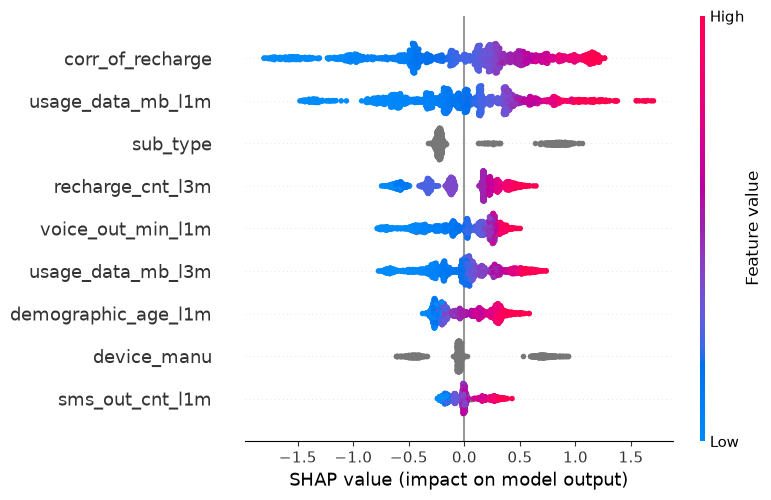

In [17]:
from train_model.evaluation import plot_shap_summary, shap_group_importance, shap_importance

X_test = prepare_features(test, final_features, cat_final)
shap_imp = shap_importance(model, X_test, max_samples=3000)
display(shap_imp)
display(shap_group_importance(shap_imp))
plot_shap_summary(model, X_test.sample(min(2000, len(X_test)), random_state=0), max_display=15);

## 10a. Drift — event PSI, PSI theo trọng số model, SHAP drift

* `psi` (volume) — phân phối feature dịch bao nhiêu. `event_psi` — phân phối **các dòng khách xấu** giữa các bin dịch bao nhiêu
  (`event_label` = nhãn của khách xấu: label 1 = good thì `event_label=0`):
  volume có thể đứng yên trong khi rủi ro dồn sang bin khác.
* `weight` = tỉ trọng mean |SHAP| → `weighted_*` cho biết drift của feature **quan trọng với model** đến mức nào; dòng `(model)` = tổng.
* `shap_drift` — mean |SHAP| từng feature train vs test (Welch t-test): model có dựa vào feature khác đi trên data mới không.

Ý tưởng *Lift PSI* và *SHAP drift* từ [AIDflow](https://github.com/aigensys-labs/aidflow), viết lại.

In [18]:
from train_model.evaluation import psi_report, shap_drift

bad_label = 0 if cfg.scoring["target_label"] == "good" else 1
display(psi_report(train, test, final_features, TARGET, importance=shap_imp.set_index("feature")["mean_abs_shap"],
                   event_label=bad_label).round(4))
X_train = prepare_features(train, final_features, cat_final)
display(shap_drift(model, X_train, X_test).round(4))

,feature,psi,event_psi,psi_status,event_psi_status,weight,weighted_psi,weighted_event_psi
0,corr_of_recharge,0.0096,0.0103,stable,stable,0.2105,0.0020,0.0022
1,usage_data_mb_l1m,0.0044,0.0090,stable,stable,0.1609,0.0007,0.0014
2,sub_type,0.0010,0.0008,stable,stable,0.1287,0.0001,0.0001
3,recharge_cnt_l3m,0.0038,0.0014,stable,stable,0.1142,0.0004,0.0002
4,voice_out_min_l1m,0.0098,0.0169,stable,stable,0.0929,0.0009,0.0016
5,usage_data_mb_l3m,0.0143,0.0123,stable,stable,0.0875,0.0013,0.0011
6,demographic_age_l1m,0.0045,0.0058,stable,stable,0.0817,0.0004,0.0005
7,device_manu,0.0031,0.0028,stable,stable,0.0808,0.0002,0.0002
8,sms_out_cnt_l1m,0.0079,0.0120,stable,stable,0.0428,0.0003,0.0005
9,(model),NaN,NaN,NaN,NaN,1.0000,0.0064,0.0078


,feature,ref_mean_abs_shap,cur_mean_abs_shap,delta,rel_delta,t,p_value,significant
0,corr_of_recharge,0.5556,0.5669,0.0113,0.0203,1.0413,0.2978,False
1,usage_data_mb_l1m,0.4400,0.4333,-0.0068,-0.0154,-0.7350,0.4624,False
2,sub_type,0.3541,0.3465,-0.0076,-0.0216,-1.1792,0.2384,False
3,recharge_cnt_l3m,0.3109,0.3074,-0.0035,-0.0112,-0.8258,0.4090,False
4,voice_out_min_l1m,0.2470,0.2502,0.0032,0.0128,0.7594,0.4477,False
5,usage_data_mb_l3m,0.2413,0.2357,-0.0055,-0.0230,-1.0497,0.2939,False
6,device_manu,0.2204,0.2175,-0.0029,-0.0131,-0.4110,0.6811,False
7,demographic_age_l1m,0.2170,0.2201,0.0031,0.0144,1.1966,0.2315,False
8,sms_out_cnt_l1m,0.1161,0.1152,-0.0009,-0.0075,-0.3279,0.7430,False


## 10b. Challenger: scorecard logistic + so sánh champion / challenger

`LogisticScorecard` = logistic regression trên WoE + **bảng điểm từng bin** (PDO 20, 600 điểm ↔ odds good:bad 50:1) —
model minh bạch mà hội đồng rủi ro đọc được, dùng làm challenger cho CatBoost trên **cùng feature**.

`interactions=True` thêm **luật tương tác** (`TreeRuleMiner`): train cây nông trên ma trận WoE, mỗi đường gốc→lá là một luật
(`A & B`), lọc qua support → trùng lặp (Simpson) → tương quan → Lasso. Mỗi luật được chọn có một dòng điểm riêng trong bảng
(cộng điểm khi luật đúng), mô tả bằng bin gốc. Scorecard vẫn minh bạch nhưng bắt được tương tác như cây.
Cây bắt đầu từ chính logistic WoE và luật được chọn trên **phần dư** (Lasso, quy tắc 1-SE) → chỉ giữ luật bổ sung điều scorecard chưa có.
> Data giả lập ở đây là **cộng tính** (không có tương tác thật) nên miner chọn **0 luật** — kết quả đúng. Trên data có tương tác
> (vd. `x1 > a` **và** `x2 > b` mới rủi ro), test cho thấy miner tìm ra cặp đó và Gini scorecard tăng.

`compare_models` so sánh trên test (out-of-time) bằng nhiều tiêu chí thay vì chỉ Gini, mỗi tiêu chí chuẩn hoá theo model dẫn đầu (= 1):

| Tiêu chí | Ý nghĩa | Tốt khi |
|---|---|---|
| `gini`, `ks` | phân tách | cao |
| `calibration` | tỉ lệ bin xác suất không lệch có ý nghĩa | cao |
| `audited` | model khác tìm được nhóm rủi ro khác biệt **bên trong** bin của model này (điểm mù) | thấp |
| `auditor` | model này tìm được điểm mù của model khác | cao |
| `exposure` | số feature hiệu dụng = exp(entropy importance) | thấp |
| `max_share` | tỉ trọng feature quan trọng nhất (rủi ro phụ thuộc 1 feature) | thấp |

`cmp.delong` — kiểm định DeLong: chênh lệch Gini giữa hai model có **ý nghĩa thống kê** không (cùng tập test nên phải tính tương quan).

Ý tưởng từ bước *Agents Comparator / Transition*, *TreeMiner* và *TestModelDiff* của [AIDflow](https://github.com/aigensys-labs/aidflow), viết lại.
Bước 11–12 vẫn dùng CatBoost; bảng này là thông tin để quyết định có đổi model hay không.

> ⚠️ So sánh này chạy trên **test**. Nếu dựa vào nó để đổi champion thì Gini test của model được chọn không còn là ước lượng
> khách quan nữa — cần thêm một tập holdout (vd. tháng mới nhất chưa dùng) để báo cáo con số cuối.

In [19]:
import numpy as np

from train_model.evaluation import auc_gini, compare_models
from train_model.modeling import LogisticScorecard

card_kw = dict(features=final_features, cat_cols=cat_final, target_label=cfg.scoring["target_label"])
card_plain = LogisticScorecard(**card_kw).fit(train, train[TARGET])
card = LogisticScorecard(**card_kw, interactions=True, interaction_params=cfg.interactions).fit(train, train[TARGET])
proba_plain = card_plain.predict_proba(test)[:, 1]
proba_card = card.predict_proba(test)[:, 1]
print(f"Scorecard gini test: không tương tác = {auc_gini(test[TARGET], proba_plain)['gini']:.4f} | "
      f"có tương tác = {auc_gini(test[TARGET], proba_card)['gini']:.4f}")
print("số luật sau từng bước lọc:", card.miner_.n_rules_)
display(card.miner_.stats_.round(4))
table = card.points_table()
display(table[table["feature"].str.startswith("ixn_")].round(3))
display(table[~table["feature"].str.startswith("ixn_")].round(3))

Scorecard gini test: không tương tác = 0.6022 | có tương tác = 0.6022
số luật sau từng bước lọc: {'extracted': 337, 'support': 191, 'simpson': 76, 'phi_corr': 76, 'lasso': 0}


,name,rule,length,support,target_rate,n_target,lasso_coef


,feature,bin,count,event_rate,woe,coef,points


,feature,bin,count,event_rate,woe,coef,points
0,(base),,NaN,NaN,NaN,-0.655,468.236
1,corr_of_recharge,"(-inf, 18849.73)",279.0,0.079,1.803,-1.304,-67.867
2,corr_of_recharge,"[18849.73, 35103.39)",459.0,0.172,0.916,-1.304,-34.474
3,corr_of_recharge,"[35103.39, 52021.02)",583.0,0.252,0.433,-1.304,-16.277
4,corr_of_recharge,"[52021.02, 62286.58)",394.0,0.259,0.397,-1.304,-14.944
...,...,...,...,...,...,...,...
82,sms_out_cnt_l1m,"[13.50, 17.50)",1786.0,0.338,0.017,-1.377,-0.663
83,sms_out_cnt_l1m,"[17.50, 19.50)",577.0,0.388,-0.200,-1.377,7.941
84,sms_out_cnt_l1m,"[19.50, inf)",576.0,0.415,-0.311,-1.377,12.359
85,sms_out_cnt_l1m,Special,0.0,0.000,0.000,-1.377,-0.000


champion: scorecard


,gini,ks,calibration,exposure,max_share,audited,auditor
model,,,,,,,
catboost,0.5983,0.4625,0.8,8.2511,0.2105,0.0049,0.0035
scorecard,0.6022,0.4541,0.7,8.5247,0.1990,0.0035,0.0049


,gini,ks,calibration,auditor,audited,exposure,max_share,composite
model,,,,,,,,
scorecard,1.000,0.982,0.875,1.000,1.000,0.968,1.000,0.975
catboost,0.993,1.000,1.000,0.713,0.713,1.000,0.945,0.909


,model_1,model_2,auc_1,auc_2,gini_diff,gini_diff_low,gini_diff_high,z,p_value,significant
0,catboost,scorecard,0.7991,0.8011,-0.004,-0.0157,0.0078,-0.6593,0.5097,False


,audited,auditor,up,down,total
0,catboost,scorecard,0.0049,0.0000,0.0049
1,scorecard,catboost,0.0000,-0.0035,0.0035


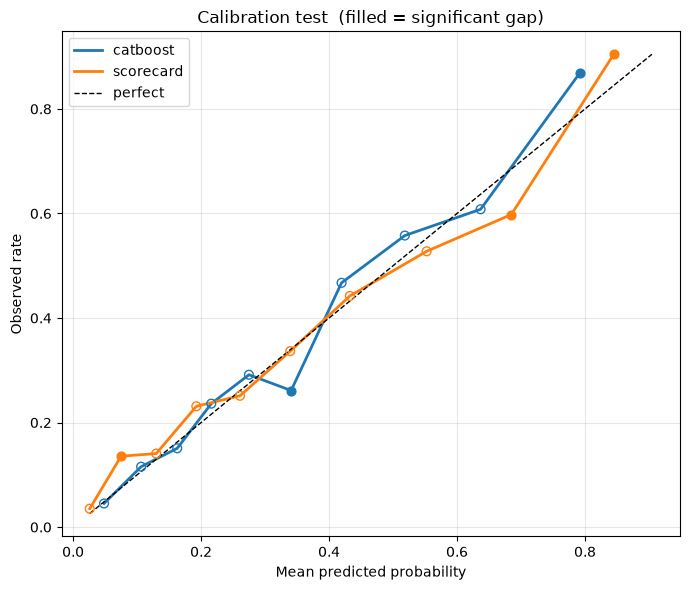

In [20]:
woe_test = card.woe_.transform(test[card.features_]).astype(float)
importances = {
    "catboost": shap_imp.set_index("feature")["mean_abs_shap"],
    "scorecard": (card.coef_[card.features_].abs() * woe_test.std()).rename("importance"),
}
cmp = compare_models(test[TARGET], {"catboost": proba["test"], "scorecard": proba_card}, importances=importances)
print("champion:", cmp.champion)
display(cmp.metrics.round(4))
display(cmp.scaled.round(3))
display(cmp.delong.round(4))
display(cmp.audit.pairs.round(4))
plot_calibration({"catboost": (test[TARGET], proba["test"]), "scorecard": (test[TARGET], proba_card)}, title="Calibration test");

## 10c. Ablation — bỏ từng feature thì mất bao nhiêu Gini?

* **Scorecard**: tính giải tích (công thức xoá trên Hessian + 2 bước Newton, có tính phạt L2 của `LogisticRegression`) — không train lại,
  khớp với fit lại thật (sai số Gini ≤ 0.002 trong test).
* **CatBoost**: `refit_ablation` train lại một lần cho mỗi feature bị bỏ.

`delta_gini < 0` = feature có ích; `significant` = mức giảm vượt nhiễu (DeLong). Feature không significant là ứng viên để bỏ cho model gọn hơn.

> ⚠️ Tính trên **test** để hiểu model. Nếu thật sự bỏ feature dựa trên bảng này thì cũng như trên: cần holdout khác để báo cáo Gini cuối.
Ý tưởng *FeatureAblation* từ [AIDflow](https://github.com/aigensys-labs/aidflow), viết lại.

In [21]:
from train_model.evaluation import refit_ablation

display(card.ablation(train, train[TARGET], test, test[TARGET]).round(4))

def catboost_fit_predict(cols):
    m = train_catboost(train, val, cols, TARGET, cat_features=[c for c in cols if c in CAT_COLS],
                       params=cfg.catboost, seed=cfg.split.seed)
    return m.predict_proba(prepare_features(test, cols, [c for c in cols if c in CAT_COLS]))[:, 1]

display(refit_ablation(catboost_fit_predict, final_features, test[TARGET]).round(4))

,feature,gini_full,gini_without,delta_gini,p_value,significant
0,corr_of_recharge,0.6022,0.4799,-0.1223,0.0000,True
1,usage_data_mb_l1m,0.6022,0.5592,-0.0430,0.0000,True
2,device_manu,0.6022,0.5665,-0.0358,0.0000,True
3,recharge_cnt_l3m,0.6022,0.5705,-0.0318,0.0000,True
4,sub_type,0.6022,0.5851,-0.0171,0.0465,True
5,usage_data_mb_l3m,0.6022,0.5905,-0.0117,0.0553,False
6,voice_out_min_l1m,0.6022,0.5969,-0.0053,0.4357,False
7,demographic_age_l1m,0.6022,0.5973,-0.0049,0.3689,False
8,sms_out_cnt_l1m,0.6022,0.5979,-0.0043,0.2992,False


,feature,gini_full,gini_without,delta_gini,p_value,significant
0,corr_of_recharge,0.5983,0.4724,-0.1259,0.0000,True
1,usage_data_mb_l1m,0.5983,0.5526,-0.0456,0.0000,True
2,device_manu,0.5983,0.5557,-0.0426,0.0000,True
3,recharge_cnt_l3m,0.5983,0.5641,-0.0342,0.0000,True
4,sub_type,0.5983,0.5784,-0.0199,0.0369,True
5,usage_data_mb_l3m,0.5983,0.5832,-0.0151,0.0113,True
6,demographic_age_l1m,0.5983,0.5917,-0.0066,0.2311,False
7,voice_out_min_l1m,0.5983,0.5930,-0.0053,0.4184,False
8,sms_out_cnt_l1m,0.5983,0.5965,-0.0018,0.6530,False


## 11. Quy đổi xác suất → điểm 300–850

`fit_score_bounds` tính khoảng điểm trên **train** và lưu vào model → điểm các tháng sau cùng một thang, không bị
kéo giãn theo từng batch.

score bounds (raw): (-5.803675197833965, 2.928805394535656)


,top,count,n_positive,acc_positive,positive_rate,acc_positive_rate,cover_positive,proba_range,score_range
0,1,199,173,173,0.869347,0.869347,0.241283,"[0.698, 0.976]","[715, 850]"
1,2,199,121,294,0.608040,0.738693,0.410042,"[0.575, 0.697]","[679, 715]"
2,3,199,111,405,0.557789,0.678392,0.564854,"[0.463, 0.575]","[660, 679]"
3,4,199,93,498,0.467337,0.625628,0.694561,"[0.376, 0.463]","[640, 660]"
4,5,199,52,550,0.261307,0.552764,0.767085,"[0.307, 0.376]","[617, 639]"
5,6,199,58,608,0.291457,0.509213,0.847978,"[0.246, 0.307]","[592, 617]"
6,7,199,47,655,0.236181,0.470208,0.913529,"[0.189, 0.245]","[563, 592]"
7,8,199,30,685,0.150754,0.430276,0.955370,"[0.136, 0.189]","[525, 563]"
8,9,199,23,708,0.115578,0.395310,0.987448,"[0.077, 0.135]","[460, 525]"
9,10,199,9,717,0.045226,0.360302,1.000000,"[0.007, 0.076]","[300, 459]"


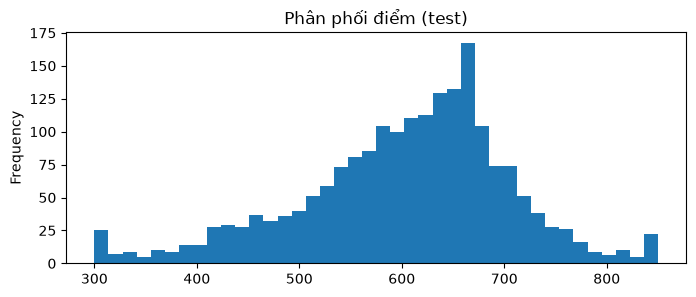

In [22]:
from train_model.scoring import fit_score_bounds, proba_to_score

sc = cfg.scoring
score_kw = dict(target_label=sc["target_label"], pct_lb=sc["pct_lb"], pct_ub=sc["pct_ub"], exponent=sc["exponent"])
bounds = fit_score_bounds(proba["train"], **score_kw)
test_score = proba_to_score(proba["test"], lower=sc["lower"], upper=sc["upper"], bounds=bounds, **score_kw)

print("score bounds (raw):", bounds)
display(decile_table(test[TARGET], proba["test"], score=test_score))
pd.Series(test_score).plot.hist(bins=40, figsize=(8, 3), title="Phân phối điểm (test)");

## 12. Lưu model

`artifacts/<model_code>/model.cbm` + `meta.json` (features, cột cat, cách fill missing, score bounds, metrics).
Bundle này là input của notebook `02_predict_spark.ipynb` và `scripts/predict_spark.py`.

In [23]:
from train_model.modeling import ModelBundle

bundle = ModelBundle(
    model=model,
    features=final_features,
    cat_features=cat_final,
    target=TARGET,
    model_code=cfg.model.model_code,
    cat_fill=cfg.features.cat_fill,
    num_fill=cfg.features.num_fill,
    train_period=(int(train[DATE].min()), int(train[DATE].max())),
    score_bounds=bounds,
    metrics=metrics.set_index("split")["gini"].round(4).to_dict(),
)
out_dir = bundle.save(ROOT / cfg.paths["artifacts_dir"] / cfg.model.model_code)
print("saved to", out_dir)

# kiểm tra: load lại và predict trên data thô (chưa fill) phải ra cùng kết quả
reloaded = ModelBundle.load(out_dir)
assert np.allclose(reloaded.predict_proba(test_raw), proba["test"])
print("reload OK —", reloaded.metrics)

saved to artifacts/demo_cs_v1
reload OK — {'train': 0.678, 'val': 0.6624, 'test': 0.5983}


## Bước tiếp theo

* Predict hàng loạt trên Spark: `notebooks/02_predict_spark.ipynb` hoặc
  `spark-submit scripts/predict_spark.py --config ... --model-dir ... --input ... --output ...`
* Các tiện ích khác: `train_model.modeling.CatBoostEnsembleClassifier` (ensemble),
  `CatBoostTransferLearner` (fine-tune trên data mới), `CatBoostShrinker` (cắt bớt cây),
  `train_model.feature_selection.WoETransformer` (WoE), `train_model.preprocessing` (encoder, imputer, winsorizer).
* So sánh / thay model: `train_model.evaluation.compare_models`, `cross_audit`, `calibration_table`; scorecard minh bạch: `LogisticScorecard.points_table()`.
* Kiểm định / drift: `delong_test`, `auc_ci`, `psi_report`, `shap_drift`; luật tương tác dùng riêng: `train_model.feature_selection.TreeRuleMiner`.
